In [54]:
from tbparse import SummaryReader
import seaborn as sns
from matplotlib import pyplot as plt

In [ ]:
logdir = "runs"
reader = SummaryReader(logdir, extra_columns={"dir_name"})

In [ ]:
data = reader.scalars
data.rename(columns={"dir_name": "run_name"}, inplace=True)
data["run_name"].unique(), data["tag"].unique()
data["run_category"] = data["run_name"].str.split("_").str[:-2].str.join("_")

<Axes: xlabel='step', ylabel='value'>

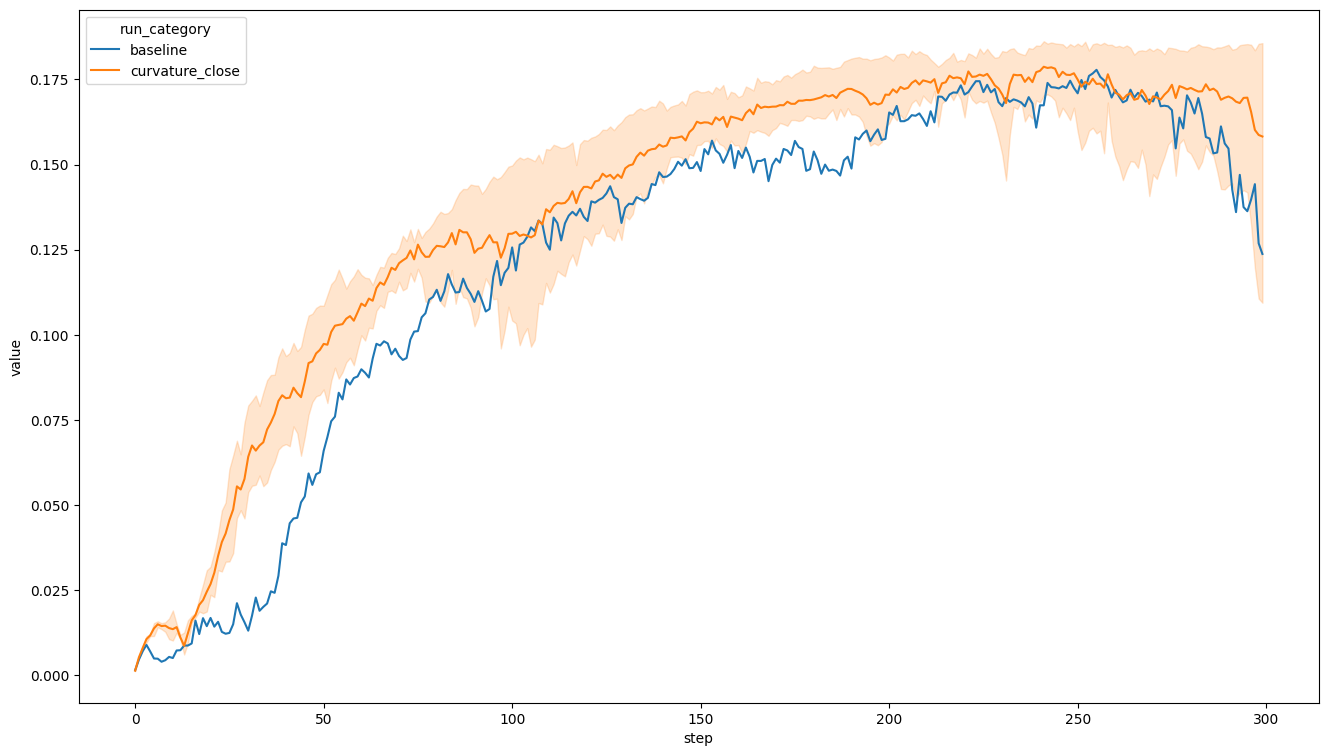

In [64]:
plt.figure(figsize=(16, 9))


sns.lineplot(
    data=data[(data["tag"] == "reward/mean") & (data["run_category"].isin(["baseline", "curvature_close"]))],
    x="step",
    y="value",
    hue="run_category",
    errorbar=("pi", 95)
)